# Questão 10 - Planejamento de rotas para entregas urbanas

O agente precisa sair do centro de distribuição A e chegar ao destino I gastando o menor tempo possível. O mapa é um grafo não direcionado com nove localidades e os custos são dados em minutos.

## 1. Formulação do problema

**Estados:** a localidade onde o entregador está. São nove estados: A, B, C, D, E, F, G, H e I.

**Estado inicial:** A.

**Ações:** em cada localidade, o entregador pode ir para qualquer localidade vizinha. Por exemplo, em A as ações são ir para B ou ir para D.

**Função de transição:** resultado(s, ir para v) = v, desde que exista um trecho entre s e v.

**Teste de objetivo:** o estado atual é I.

**Função de custo:** o custo de cada passo é o tempo do trecho percorrido. O custo do caminho é a soma dos custos dos trechos.

In [1]:
import heapq
from collections import deque

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

trechos = [
    ("A", "B", 4), ("A", "D", 3), ("B", "C", 5), ("B", "E", 2),
    ("C", "F", 2), ("D", "E", 4), ("D", "G", 6), ("E", "F", 3),
    ("E", "H", 5), ("F", "I", 4), ("G", "H", 3), ("H", "I", 2),
]
h = {"A": 10, "B": 8, "C": 6, "D": 9, "E": 6, "F": 4, "G": 5, "H": 2, "I": 0}

grafo = {}
for a, b, c in trechos:
    grafo.setdefault(a, {})[b] = c
    grafo.setdefault(b, {})[a] = c

INICIO, OBJETIVO = "A", "I"


def vizinhos(no):
    return sorted(grafo[no].items())


def custo_rota(rota):
    return sum(grafo[a][b] for a, b in zip(rota, rota[1:]))

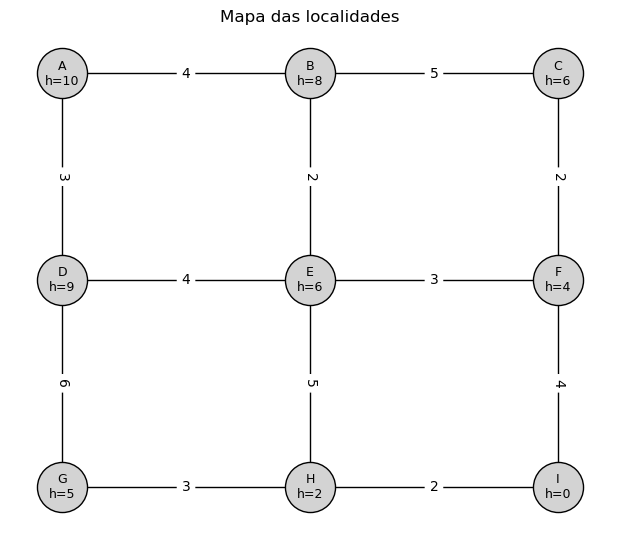

In [2]:
G = nx.Graph()
G.add_weighted_edges_from(trechos)
pos = {"A": (0, 2), "B": (1, 2), "C": (2, 2), "D": (0, 1), "E": (1, 1), "F": (2, 1), "G": (0, 0), "H": (1, 0), "I": (2, 0)}

plt.figure(figsize=(6, 5))
nx.draw(G, pos, with_labels=True, node_color="lightgray", node_size=1300, edgecolors="black",
        labels={n: f"{n}\nh={h[n]}" for n in G}, font_size=9)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))
plt.title("Mapa das localidades")
plt.show()

## 2. Busca não informada

O enunciado fala em "Busca em Profundidade (BFS)". Como o nome indica busca em profundidade e a sigla indica busca em largura, as duas foram executadas. Na comparação final a busca em profundidade é a principal, porque é ela que o enunciado cita por extenso.

Nas três buscas os vizinhos são gerados em ordem alfabética e um nó já expandido não é expandido de novo.

**Busca em profundidade (DFS)**

Usa uma pilha. Sempre expande o nó mais recente da fronteira, então desce por um caminho até não ter mais para onde ir.

In [3]:
def dfs(inicio, objetivo):
    pilha = [[inicio]]
    expandidos = []
    while pilha:
        rota = pilha.pop()
        no = rota[-1]
        if no in expandidos:
            continue
        expandidos.append(no)
        if no == objetivo:
            return rota, expandidos
        # empilha ao contrário para o menor vizinho sair primeiro
        for viz, _ in reversed(vizinhos(no)):
            if viz not in expandidos:
                pilha.append(rota + [viz])
    return None, expandidos


rota_dfs, exp_dfs = dfs(INICIO, OBJETIVO)
print("Ordem de expansão:", " -> ".join(exp_dfs))
print("Rota encontrada:  ", " -> ".join(rota_dfs))
print("Custo total:      ", custo_rota(rota_dfs), "min")

Ordem de expansão: A -> B -> C -> F -> E -> D -> G -> H -> I
Rota encontrada:   A -> B -> C -> F -> E -> D -> G -> H -> I
Custo total:       29 min


**Busca em largura (BFS)**

Usa uma fila. Expande primeiro todos os nós de um nível antes de passar para o próximo. Acha a rota com menos trechos, não a de menor tempo.

In [4]:
def bfs(inicio, objetivo):
    fila = deque([[inicio]])
    expandidos = []
    while fila:
        rota = fila.popleft()
        no = rota[-1]
        if no in expandidos:
            continue
        expandidos.append(no)
        if no == objetivo:
            return rota, expandidos
        for viz, _ in vizinhos(no):
            if viz not in expandidos:
                fila.append(rota + [viz])
    return None, expandidos


rota_bfs, exp_bfs = bfs(INICIO, OBJETIVO)
print("Ordem de expansão:", " -> ".join(exp_bfs))
print("Rota encontrada:  ", " -> ".join(rota_bfs))
print("Custo total:      ", custo_rota(rota_bfs), "min")

Ordem de expansão: A -> B -> D -> C -> E -> G -> F -> H -> I
Rota encontrada:   A -> B -> C -> F -> I
Custo total:       15 min


**Busca com custo uniforme (UCS)**

Usa uma fila de prioridade ordenada por g(n), o custo acumulado desde A. Sempre expande o nó mais barato da fronteira. Em caso de empate, sai primeiro o nó de menor letra.

In [5]:
def busca_melhor_primeiro(inicio, eh_objetivo, sucessores, heuristica=lambda s: 0):
    fronteira = [(heuristica(inicio), inicio, 0, [inicio])]
    melhor_g = {}
    passos = []
    while fronteira:
        f, estado, g, rota = heapq.heappop(fronteira)
        if estado in melhor_g:
            continue
        melhor_g[estado] = g
        passos.append({"expandido": estado, "g": g, "h": heuristica(estado), "f": f, "rota": rota})
        if eh_objetivo(estado):
            return rota, g, passos
        for prox, custo in sucessores(estado):
            if prox not in melhor_g:
                g2 = g + custo
                heapq.heappush(fronteira, (g2 + heuristica(prox), prox, g2, rota + [prox]))
    return None, None, passos


def tabela(passos, com_h=False):
    df = pd.DataFrame(passos)
    df["rota"] = df["rota"].apply(lambda r: "-".join(map(str, r)))
    colunas = ["expandido", "g", "h", "f", "rota"] if com_h else ["expandido", "g", "rota"]
    df = df[colunas]
    df.index = range(1, len(df) + 1)
    return df


rota_ucs, custo_ucs, passos_ucs = busca_melhor_primeiro(INICIO, lambda s: s == OBJETIVO, vizinhos)
print("Ordem de expansão:", " -> ".join(p["expandido"] for p in passos_ucs))
print("Rota encontrada:  ", " -> ".join(rota_ucs))
print("Custo total:      ", custo_ucs, "min")
tabela(passos_ucs)

Ordem de expansão: A -> D -> B -> E -> C -> F -> G -> H -> I
Rota encontrada:   A -> B -> E -> F -> I
Custo total:       13 min


,expandido,g,rota
1,A,0,A
2,D,3,A-D
3,B,4,A-B
4,E,6,A-B-E
5,C,9,A-B-C
6,F,9,A-B-E-F
7,G,9,A-D-G
8,H,11,A-B-E-H
9,I,13,A-B-E-F-I


A UCS expande todos os nós com custo menor que 13 antes de chegar em I. Existem duas rotas ótimas com 13 minutos: A-B-E-F-I e A-B-E-H-I. A que aparece depende apenas do critério de desempate.

## 3. Busca informada (A*)

A fila de prioridade passa a ser ordenada por f(n) = g(n) + h(n), em que g(n) é o custo já gasto e h(n) é a estimativa do que falta até I.

Antes de rodar, vale conferir se a heurística dada é admissível (nunca passa do custo real até I) e consistente (h(n) <= custo(n, v) + h(v) para todo trecho).

In [6]:
custo_real = nx.single_source_dijkstra_path_length(G, OBJETIVO)
conf = pd.DataFrame({"h(n)": h, "custo real até I": custo_real}).sort_index()
conf["admissível"] = conf["h(n)"] <= conf["custo real até I"]
print("Consistente:", all(h[a] <= c + h[b] and h[b] <= c + h[a] for a, b, c in trechos))
conf.T

Consistente: True


,A,B,C,D,E,F,G,H,I
h(n),10,8,6,9,6,4,5,2,0
custo real até I,13,9,6,11,7,4,5,2,0
admissível,True,True,True,True,True,True,True,True,True


In [7]:
rota_a, custo_a, passos_a = busca_melhor_primeiro(INICIO, lambda s: s == OBJETIVO, vizinhos, lambda s: h[s])
print("Ordem de expansão:", " -> ".join(p["expandido"] for p in passos_a))
print("Rota encontrada:  ", " -> ".join(rota_a))
print("Custo total:      ", custo_a, "min")
tabela(passos_a, com_h=True)

Ordem de expansão: A -> B -> D -> E -> F -> H -> I
Rota encontrada:   A -> B -> E -> F -> I
Custo total:       13 min


,expandido,g,h,f,rota
1,A,0,10,10,A
2,B,4,8,12,A-B
3,D,3,9,12,A-D
4,E,6,6,12,A-B-E
5,F,9,4,13,A-B-E-F
6,H,11,2,13,A-B-E-H
7,I,13,0,13,A-B-E-F-I


Valores de g, h e f de todos os nós que entraram na fronteira durante o A*, na ordem em que foram gerados:

In [8]:
def nos_gerados(inicio, objetivo):
    linhas = [{"nó": inicio, "pai": "-", "g": 0, "h": h[inicio], "f": h[inicio]}]
    fechados = set()
    for p in passos_a:
        no = p["expandido"]
        fechados.add(no)
        if no == objetivo:
            break
        for viz, c in vizinhos(no):
            if viz not in fechados:
                g2 = p["g"] + c
                linhas.append({"nó": viz, "pai": no, "g": g2, "h": h[viz], "f": g2 + h[viz]})
    return pd.DataFrame(linhas)


nos_gerados(INICIO, OBJETIVO)

,nó,pai,g,h,f
0,A,-,0,10,10
1,B,A,4,8,12
2,D,A,3,9,12
3,C,B,9,6,15
4,E,B,6,6,12
5,E,D,7,6,13
6,G,D,9,5,14
7,F,E,9,4,13
8,H,E,11,2,13
9,C,F,11,6,17


O A* expande A, B, D e E, todos com f menor que 13, e depois F, H e I, com f = 13. Os nós C e G têm f igual a 15 e 14 e nunca são expandidos, porque a rota ótima é encontrada antes. Como a heurística é admissível e consistente, a rota de 13 minutos é ótima.

## 4. Comparação

In [9]:
comparacao = pd.DataFrame(
    [
        ["Profundidade (DFS)", "-".join(rota_dfs), custo_rota(rota_dfs), len(exp_dfs), "Sim, em grafo finito com controle de repetidos", "Não"],
        ["Largura (BFS)", "-".join(rota_bfs), custo_rota(rota_bfs), len(exp_bfs), "Sim", "Só se todos os custos forem iguais"],
        ["Custo uniforme (UCS)", "-".join(rota_ucs), custo_ucs, len(passos_ucs), "Sim, com custos positivos", "Sim"],
        ["A*", "-".join(rota_a), custo_a, len(passos_a), "Sim", "Sim, com heurística admissível"],
    ],
    columns=["Algoritmo", "Rota", "Custo (min)", "Nós expandidos", "Completude", "Otimalidade"],
)
comparacao

,Algoritmo,Rota,Custo (min),Nós expandidos,Completude,Otimalidade
0,Profundidade (DFS),A-B-C-F-E-D-G-H-I,29,9,"Sim, em grafo finito com controle de repetidos",Não
1,Largura (BFS),A-B-C-F-I,15,9,Sim,Só se todos os custos forem iguais
2,Custo uniforme (UCS),A-B-E-F-I,13,9,"Sim, com custos positivos",Sim
3,A*,A-B-E-F-I,13,7,Sim,"Sim, com heurística admissível"


A busca em profundidade encontra uma rota, mas ela é bem pior que a ótima, porque o algoritmo não olha para os custos e aceita o primeiro caminho que chega em I. Sem o controle de nós repetidos ela poderia ficar presa em ciclos, então em geral não é completa.

A busca em largura chega em I com quatro trechos, que é o menor número de trechos possível, mas a rota custa 15 minutos. Ela minimiza a quantidade de trechos e não o tempo, por isso não é ótima quando os custos são diferentes.

A busca com custo uniforme garante a rota ótima, mas expande quase o grafo inteiro, pois avança em todas as direções.

O A* também garante a rota ótima e expande menos nós, porque a heurística empurra a busca na direção de I.

## 5. Visita obrigatória a D e F

Agora o entregador precisa passar por D e por F, em qualquer ordem, antes de terminar em I. Só a localidade atual não é mais suficiente como estado, porque o agente precisa lembrar o que já visitou.

**Nova representação de estado:** uma tupla (local, visitouD, visitouF).

**Estado inicial:** (A, False, False).

**Ações e transição:** as mesmas de antes. Ao entrar em D o segundo campo vira True e ao entrar em F o terceiro campo vira True.

**Teste de objetivo:** local = I, visitouD = True e visitouF = True.

**Custo:** o mesmo, a soma dos tempos dos trechos.

O espaço de estados passa de 9 para 9 x 2 x 2 = 36 estados. A heurística original continua admissível, pois as novas exigências só podem aumentar o custo real.

In [10]:
def sucessores_v(estado):
    local, d, f = estado
    return [((viz, d or viz == "D", f or viz == "F"), c) for viz, c in vizinhos(local)]


def objetivo_v(estado):
    return estado == (OBJETIVO, True, True)


inicio_v = (INICIO, False, False)
rota_v, custo_v, passos_v = busca_melhor_primeiro(inicio_v, objetivo_v, sucessores_v, lambda s: h[s[0]])

print("Rota:", " -> ".join(s[0] for s in rota_v))
print("Custo total:", custo_v, "min")
print("Estados expandidos:", len(passos_v))

pd.DataFrame(
    [{"local": s[0], "visitou D": s[1], "visitou F": s[2], "g": custo_rota([x[0] for x in rota_v[: i + 1]])} for i, s in enumerate(rota_v)]
)

Rota: A -> D -> E -> F -> I
Custo total: 14 min
Estados expandidos: 14


,local,visitou D,visitou F,g
0,A,False,False,0
1,D,True,False,3
2,E,True,False,7
3,F,True,True,10
4,I,True,True,14


A rota de menor custo é A-D-E-F-I, com 14 minutos. Ela custa 1 minuto a mais que a rota ótima do problema original, que não passava por D.

Para conferir, a UCS no novo espaço de estados deve chegar ao mesmo custo:

In [11]:
_, custo_conf, passos_conf = busca_melhor_primeiro(inicio_v, objetivo_v, sucessores_v)
print("Custo pela UCS:", custo_conf, "min |", len(passos_conf), "estados expandidos")

Custo pela UCS: 14 min | 24 estados expandidos
